In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# How do I run two phases parallel-in-time?

Complex models sometimes encounter state variables which are best simulated on different time scales, with some state variables changing quickly (fast variables) and some evolving slowly (slow variables).  

For instance, an aircraft trajectory optimization which includes vehicle component temperatures might see relatively gradual changes in altitude over the course of a two hour flight while temperatures of some components seem to exhibit step-function-like behavior on the same scale.

To accommodate both fast and slow variables in the same ODE, one would typically need to use a _dense_ grid (with many segments/higher order segments).
This can be unnecessarily burdensome when there are many slow variables or evaluating their rates is particularly expensive.

As a solution, Dymos allows the user to run two phases over the same range of times, where one phase may have a more sparse grid to accommodate the slow variables, and one has a more dense grid for the fast variables.

To connect the two phases, state variable values are passed from the first (slow) phase to the second (fast) phase as non-optimal dynamic control variables.
These values are then used to evaluate the rates of the fast variables.
Since outputs from the first phase in general will not fall on the appropriate grid points to be used by the second phase, interpolation is necessary.  
This is one application of the interpolating timeseries component.

In the following example, we solve the brachistochrone problem but do so to minimize the arclength of the resulting wire instead of the time required for the bead to travel along the wire.  
This is a trivial solution which should find a straight line from the starting point to the ending point.

There are two phases involved, the first utilizes the standard ODE for the brachistochrone problem.
The second integrates the arclength (𝑆) of the wire using the equation:

\begin{align}
    S = \int v \sin \theta  \sqrt{1 + \frac{1}{\tan^2 \theta}} dt
\end{align}

## The ODE for the wire arclength

In [2]:
om.display_source('dymos.examples.brachistochrone.test.test_tandem_phases.BrachistochroneArclengthODE')

class BrachistochroneArclengthODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')
        self.add_input('theta', val=np.zeros(nn), desc='angle of wire', units='rad')
        self.add_output('Sdot', val=np.zeros(nn), desc='rate of change of arclength', units='m/s')

        # Setup partials
        arange = np.arange(self.options['num_nodes'])

        self.declare_partials(of='Sdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='Sdot', wrt='theta', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        v = inputs['v']
        outputs['Sdot'] = np.sqrt(1.0 + (1.0/np.tan(theta))**2) * v * np.sin(theta)

    def compute_partials(self, inputs, jacobian):
        theta = inputs['theta']
        v = inputs['v']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        tan_theta = np.tan(theta)
        cot_theta = 1.0 / tan_theta
        csc_theta = 1.0 / sin_theta

        jacobian['Sdot', 'v'] = sin_theta * np.sqrt(1.0 + cot_theta**2)
        jacobian['Sdot', 'theta'] = v * (cos_theta * (cot_theta**2 + 1) - cot_theta * csc_theta) / \
            (np.sqrt(1 + cot_theta**2))

The trick is that the bead velocity ($v$) is a state variable solved for in the first phase,
and the wire angle ($\theta$) is a control variable "owned" by the first phase.  In the
second phase they are used as control variables with option ``opt=False`` so that their values are
expected as inputs for the second phase.  We need to connect their values from the first phase
to the second phase, at the `control_input` node subset of the second phase.

In the following example, we instantiate two phases and add an interpolating timeseries to the first phase
which provides outputs at the `control_input` nodes of the second phase.  Those values are
then connected and the entire problem run. The result is that the position and velocity variables
are solved on a relatively coarse grid while the arclength of the wire is solved on a much denser grid.

In [3]:
class BrachistochroneArclengthODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')
        self.add_input('theta', val=np.zeros(nn), desc='angle of wire', units='rad')
        self.add_output('Sdot', val=np.zeros(nn), desc='rate of change of arclength', units='m/s')

        # Setup partials
        arange = np.arange(nn)

        self.declare_partials(of='Sdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='Sdot', wrt='theta', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        v = inputs['v']
        outputs['Sdot'] = np.sqrt(1.0 + (1.0 / np.tan(theta))**2) * v * np.sin(theta)

    def compute_partials(self, inputs, jacobian):
        theta = inputs['theta']
        v = inputs['v']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        tan_theta = np.tan(theta)
        cot_theta = 1.0 / tan_theta
        csc_theta = 1.0 / sin_theta

        jacobian['Sdot', 'v'] = sin_theta * np.sqrt(1.0 + cot_theta**2)
        jacobian['Sdot', 'theta'] = v * (cos_theta * (cot_theta**2 + 1) - cot_theta * csc_theta) / \
            (np.sqrt(1 + cot_theta**2))

In [4]:
om.display_source('dymos.examples.brachistochrone.brachistochrone_ode')

import numpy as np
import openmdao.api as om


class BrachistochroneODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('static_gravity', types=(bool,), default=False,
                             desc='If True, treat gravity as a static (scalar) input, rather than '
                                  'having different values at each node.')

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('v', val=np.zeros(nn), desc='velocity', units='m/s')

        if self.options['static_gravity']:
            self.add_input('g', val=9.80665, desc='grav. acceleration', units='m/s/s',
                           tags=['dymos.static_target'])
        else:
            self.add_input('g', val=9.80665 * np.ones(nn), desc='grav. acceleration', units='m/s/s')

        self.add_input('theta', val=np.ones(nn), desc='angle of wire', units='rad')

        self.add_output('xdot', val=np.zeros(nn), desc='velocity component in x', units='m/s',
                        tags=['dymos.state_rate_source:x', 'dymos.state_units:m'])

        self.add_output('ydot', val=np.zeros(nn), desc='velocity component in y', units='m/s',
                        tags=['dymos.state_rate_source:y', 'dymos.state_units:m'])

        self.add_output('vdot', val=np.zeros(nn), desc='acceleration magnitude', units='m/s**2',
                        tags=['dymos.state_rate_source:v', 'dymos.state_units:m/s'])

        self.add_output('check', val=np.zeros(nn), desc='check solution: v/sin(theta) = constant',
                        units='m/s')

        # Setup partials
        arange = np.arange(self.options['num_nodes'])
        self.declare_partials(of='vdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='xdot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='xdot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='ydot', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='ydot', wrt='theta', rows=arange, cols=arange)

        self.declare_partials(of='check', wrt='v', rows=arange, cols=arange)
        self.declare_partials(of='check', wrt='theta', rows=arange, cols=arange)

        if self.options['static_gravity']:
            c = np.zeros(self.options['num_nodes'])
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=c)
        else:
            self.declare_partials(of='vdot', wrt='g', rows=arange, cols=arange)

    def compute(self, inputs, outputs):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        outputs['vdot'] = g * cos_theta
        outputs['xdot'] = v * sin_theta
        outputs['ydot'] = -v * cos_theta
        outputs['check'] = v / sin_theta

    def compute_partials(self, inputs, partials):
        theta = inputs['theta']
        cos_theta = np.cos(theta)
        sin_theta = np.sin(theta)
        g = inputs['g']
        v = inputs['v']

        partials['vdot', 'g'] = cos_theta
        partials['vdot', 'theta'] = -g * sin_theta

        partials['xdot', 'v'] = sin_theta
        partials['xdot', 'theta'] = v * cos_theta

        partials['ydot', 'v'] = -cos_theta
        partials['ydot', 'theta'] = v * sin_theta

        partials['check', 'v'] = 1 / sin_theta
        partials['check', 'theta'] = -v * cos_theta / sin_theta ** 2

In [5]:
%matplotlib inline

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.000538 sec).


INFO: checking system...


INFO:     system check complete (0.000031 sec).


INFO: checking solvers...


...

INFO: checking comp_has_no_outputs...


INFO:     comp_has_no_outputs check complete (0.000062 sec).


/home/runner/work/dymos/dymos/.openmdao-pixi/.pixi/envs/dev/lib/python3.13/site-packages/openmdao/utils/relevance.py:1234: OpenMDAOWarning:The top level group has a nonlinear solver that computes gradients, so the entire model will be included in the optimization iteration.



Jacobian shape: (222, 287)  (8.51% nonzero)
FWD solves: 30   REV solves: 0
Total colors vs. total size: 30 vs 287  (89.55% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'tandem_phases' was computed 3 times.
Time to compute sparsity:   0.3179 sec
Time to compute coloring:   0.7811 sec
Memory to compute coloring:   7.3828 MB
Coloring created on: 2026-10-30 15:47:14




Optimization Problem -- Optimization using pyOpt_sparse
    Objective Function: _objfunc

    Solution: 
--------------------------------------------------------------------------------
    Total Time:                   11.8952
       User Objective Time :       0.3837
       User Sensitivity Time :     2.8649
       Interface Time :            0.6726
       Opt Solver Time:            7.9739
    Calls to Objective Function :     134
    Calls to Sens Function :          103


   Objectives
      Index  Name                       Value
          0  phase1.states:S     1.118119E+01

   Variables (c - continuous, i - integer, d - discrete)
      Index  Name                       Type      Lower Bound            Value      Upper Bound     Status
          0  phase0.t_duration_0           c     5.000000E-01     2.210247E+00     1.000000E+01           
          1  phase0.states:x_0             c    -1.000000E+20     1.390924E-01     1.000000E+20           
          2  phase0.states:x_1 

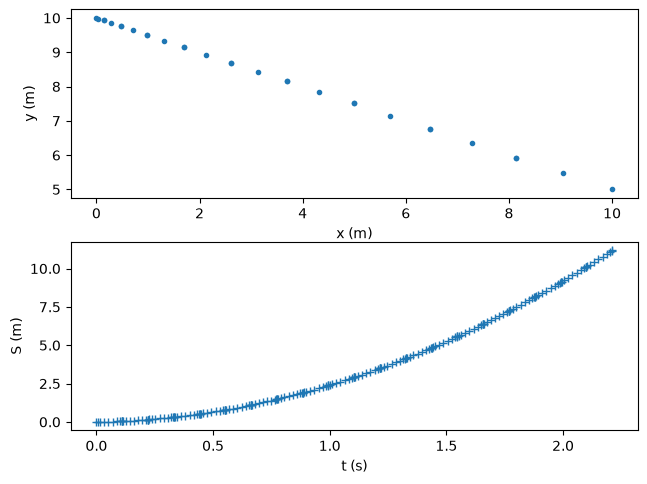

In [6]:
from dymos.examples.brachistochrone.brachistochrone_ode import BrachistochroneODE

import numpy as np
import matplotlib.pyplot as plt
import openmdao.api as om
import dymos as dm

p = om.Problem(model=om.Group())

p.driver = om.pyOptSparseDriver()
p.driver.options['optimizer'] = 'SLSQP'
p.driver.declare_coloring()

# The transcription of the first phase
tx0 = dm.GaussLobatto(num_segments=10, order=3, compressed=False)

# The transcription for the second phase (and the secondary timeseries outputs from the first phase)
tx1 = dm.Radau(num_segments=20, order=9, compressed=False)

#
# First Phase: Integrate the standard brachistochrone ODE
#
phase0 = dm.Phase(ode_class=BrachistochroneODE, transcription=tx0)

p.model.add_subsystem('phase0', phase0)

phase0.set_time_options(fix_initial=True, duration_bounds=(.5, 10))

phase0.add_state('x', fix_initial=True, fix_final=False)

phase0.add_state('y', fix_initial=True, fix_final=False)

phase0.add_state('v', fix_initial=True, fix_final=False)

phase0.add_control('theta', continuity=True, rate_continuity=True,
                   units='deg', lower=0.01, upper=179.9)

phase0.add_parameter('g', units='m/s**2', val=9.80665)

phase0.add_boundary_constraint('x', loc='final', equals=10)
phase0.add_boundary_constraint('y', loc='final', equals=5)

# Add alternative timeseries output to provide control inputs for the next phase
phase0.add_timeseries('timeseries2', transcription=tx1, subset='control_input')

#
# Second Phase: Integration of ArcLength
#
phase1 = dm.Phase(ode_class=BrachistochroneArclengthODE, transcription=tx1)

p.model.add_subsystem('phase1', phase1)

phase1.set_time_options(fix_initial=True, input_duration=True)

phase1.add_state('S', fix_initial=True, fix_final=False,
                 rate_source='Sdot', units='m')

phase1.add_control('theta', opt=False, units='deg', targets='theta')
phase1.add_control('v', opt=False, units='m/s', targets='v')

#
# Connect the two phases
#
p.model.connect('phase0.t_duration_val', 'phase1.t_duration')

p.model.connect('phase0.timeseries2.theta', 'phase1.controls:theta')
p.model.connect('phase0.timeseries2.v', 'phase1.controls:v')

# Minimize arclength at the end of the second phase
phase1.add_objective('S', loc='final', ref=1)

p.model.linear_solver = om.DirectSolver()
p.setup(check=True)

phase0.set_time_val(0.0, 2.0)

phase0.set_state_val('x', [0, 10])
phase0.set_state_val('y', [10, 5])
phase0.set_state_val('v', [0, 9.9])
phase0.set_control_val('theta', [5, 100])
phase0.set_parameter_val('g', 9.80665)

phase1.set_state_val('S', 0.0)

dm.run_problem(p)

fig, (ax0, ax1) = plt.subplots(2, 1)
fig.tight_layout()
ax0.plot(p.get_val('phase0.timeseries.x'), p.get_val('phase0.timeseries.y'), '.')
ax0.set_xlabel('x (m)')
ax0.set_ylabel('y (m)')
ax1.plot(p.get_val('phase1.timeseries.time'), p.get_val('phase1.timeseries.S'), '+')
ax1.set_xlabel('t (s)')
ax1.set_ylabel('S (m)')
plt.show()

In [7]:
from openmdao.utils.assert_utils import assert_near_equal

expected = np.sqrt((10 - 0) ** 2 + (10 - 5)**2)
assert_near_equal(p.get_val('phase1.timeseries.S')[-1], expected, tolerance=1.0E-3)

np.float64(7.590016179470925e-05)